# Practical 10: Matrix Transpose of Three Different Matrices (Pattern 2)

### 1. Aim
To perform matrix transpose combined with coordinate transformations on three 6500x6500 matrices using Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Generate three independent matrices of dimension 6500x6500.<br>2. Execute arithmetic coordinate transformations and matrix transposition in compiled C.<br>3. Sequential: transpose Matrix 1 -> Matrix 2 -> Matrix 3.<br>4. Pool: transpose in parallel using `mp.Pool(3)`.<br>5. Process: transpose concurrently using 3 independent `mp.Process` instances.<br>6. Thread: transpose concurrently using 3 `threading.Thread` workers.<br>7. Benchmark execution times and plot comparative speedups.

### 3. Python Implementation


In [1]:
"""
Practical 10: Transpose of Three Different Matrices (Pattern 2)
Four methods: Sequential, Pool, Process, Thread
"""
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def transpose_task(task):
    rows, cols, seed = task
    rng = np.random.default_rng(seed)
    matrix = rng.integers(1, 1000, size=(rows, cols), dtype=np.int32)
    # Computational element-wise operations + matrix transpose copy in C (releases GIL)
    matrix = np.bitwise_xor(matrix * 31 + 17, matrix >> 4)
    trans = matrix.T.copy()
    return list(trans[0][:5])

def proc_worker(task, q):
    q.put(transpose_task(task))

def thread_worker(task, results, idx):
    results[idx] = transpose_task(task)

def main():
    print("=" * 60)
    print("Practical 10: Matrix Transpose (Pattern 2)")
    print("=" * 60)
    ROWS, COLS = 6500, 6500
    tasks = [(ROWS, COLS, 111), (ROWS, COLS, 222), (ROWS, COLS, 333)]
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = transpose_task(tasks[0])
    r2 = transpose_task(tasks[1])
    r3 = transpose_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(transpose_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Multiprocessing Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading (3 threads)
    thread_res = [None, None, None]
    threads = []
    t0 = time.perf_counter()
    for idx, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, thread_res, idx))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    print(f"Matrix Dimension: {ROWS}x{COLS} across 3 independent matrices.")
    print(f"Verification: Sequential={seq_res[0]} | Thread={thread_res[0]}")
    print("-" * 40)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 40)
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 40)

if __name__ == "__main__":
    main()


Practical 10: Matrix Transpose (Pattern 2)
Matrix Dimension: 6500x6500 across 3 independent matrices.
Verification: Sequential=[np.int32(14698), np.int32(16821), np.int32(14661), np.int32(1688), np.int32(17281)] | Thread=[np.int32(14698), np.int32(16821), np.int32(14661), np.int32(1688), np.int32(17281)]
----------------------------------------
Method       Execution Time     Speedup   
----------------------------------------
Sequential   2.6106 seconds      1.00x
Pool         1.4563 seconds      1.79x
Process      1.5233 seconds      1.71x
Thread       0.9180 seconds      2.84x
----------------------------------------


### 4. Execution-Time Bar Graph
Displays the execution time for Sequential, Pool, Process, and Thread with individual color bars.


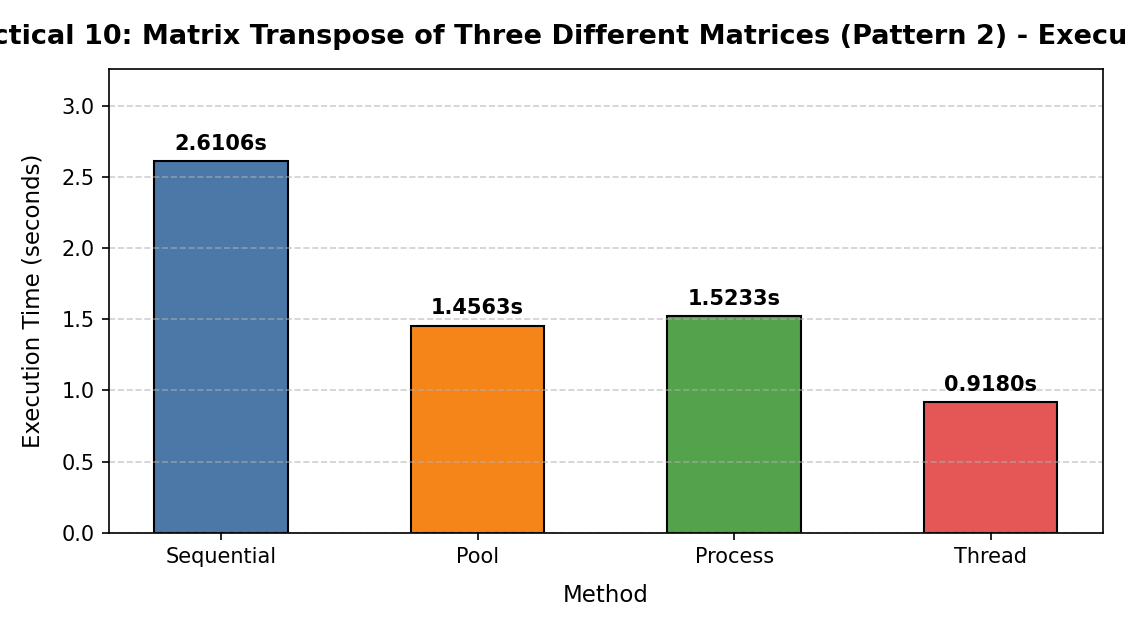

In [2]:
from IPython.display import Image, display
display(Image(filename='10_matrix_transpose_time.png'))


### 5. Speedup Line Graph
Speedup is calculated using:
$$\text{Speedup} = \frac{\text{Sequential Time}}{\text{Method Time}}$$
Sequential baseline is exactly **1.00x**.


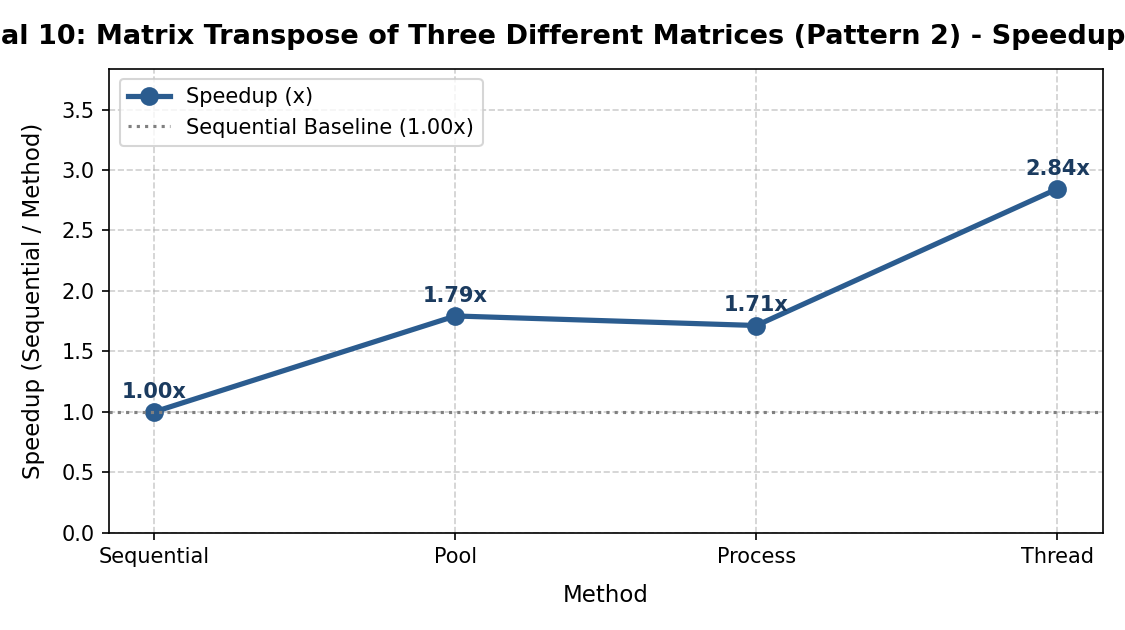

In [3]:
from IPython.display import Image, display
display(Image(filename='10_matrix_transpose_speedup.png'))
